# Machine Learning Homework 2026
## Section 1 - Import and Explore the Data


# Import the Libraries and the Data

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


FIGSIZE = (10, 6)
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"
CLASS_COLOURS = {0: PLOT_BLUE, 1: PLOT_ORANGE}


In [7]:
# `ID` identifies the row, so it goes in the index rather than sitting among
# the columns a model could be handed by accident.
train = pd.read_csv("../data/train.csv", index_col="ID")

print(f"{train.shape[0]:,} rows x {train.shape[1]} columns, indexed by ID")
train.head()

6,534 rows x 38 columns, indexed by ID


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [12]:
test = pd.read_csv("../data/test.csv", index_col="ID")
clientes = pd.read_csv("../data/clientes.csv")

print(f"test:     {test.shape[0]:,} rows and {test.shape[1]} columns")
print(f"clientes: {clientes.shape[0]:,} rows and {clientes.shape[1]} columns")
print("in train but not in test:", set(train.columns) - set(test.columns))

test:     986 rows and 37 columns
clientes: 1,143 rows and 13 columns
in train but not in test: {'repeat_purchase_90d'}


The Training data contains an extra collumn when compared to the Test data which is the **Target**, all the remaining collumns are the same. 
So we can conclude that the Target is the collumn **'repeat_purchase_90d'**

# Data Structure

In [13]:
train.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

In [12]:
train.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [16]:
train["purchase_date"] = pd.to_datetime(train["purchase_date"])
test["purchase_date"] = pd.to_datetime(test["purchase_date"])

target = "repeat_purchase_90d"
categorical = ["payment_type", "salesperson", "commercial_zone",
               "transport_method", "warehouse", "document_series"]
numeric = [c for c in train.select_dtypes("number").columns
           if c not in [target, "customer_id"]]

print(len(numeric), "numeric columns and", len(categorical), "categorical columns")

29 numeric columns and 6 categorical columns


# **Descriptive Statistics**

In [17]:
train[numeric].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.56,1335.00,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,6469.0,886.15,1327.64,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,6469.0,773.34,1136.36,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,6469.0,152.22,225.26,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,6469.0,1.15,5.84,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,6469.0,0.35,5.12,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,6469.0,112.47,289.99,0.00,0.00,13.13,92.28,4.103440e+03
Custo,6469.0,328.17,519.51,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,6469.0,21.52,27.71,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,6469.0,1.07,0.31,1.00,1.00,1.00,1.00,5.000000e+00


In [18]:
train[categorical].describe().T

,count,unique,top,freq
payment_type,6274,9,Maybe Tomorrow Payment 7,4565
salesperson,6275,9,VLOOKUP Master 1,4054
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119
warehouse,6274,2,Final Excel Warehouse 1,6253
document_series,6469,3,Ctrl Z Series 2,2738


# Data Quality

## Missing Values

In [21]:
missing = pd.DataFrame({
    "missing": train.isna().sum(),
    "% missing": (100 * train.isna().mean()).round(1),
})
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

,missing,% missing
prior_std_gap_days,1478,22.6
prior_mean_gap_days,1308,20.0
prior_std_purchase_value,1113,17.0
prior_mean_purchase_value,862,13.2
days_since_previous_purchase,861,13.2
prior_max_purchase_value,668,10.2
prior_min_purchase_value,668,10.2
transport_method,261,4.0
warehouse,260,4.0
payment_type,260,4.0


In [22]:
empty_rows = train["Total Imp_"].isna()
print("rows without 'Total Imp_':", empty_rows.sum())
print("columns that still have a value in those rows:",
      train[empty_rows].columns[train[empty_rows].notna().any()].tolist())

rows without 'Total Imp_': 65
columns that still have a value in those rows: ['repeat_purchase_90d', 'customer_id']


In [23]:
first_purchase = train["prior_purchase_count"] == 0
print("first purchases:", first_purchase.sum())

history = ["days_since_previous_purchase", "prior_mean_purchase_value",
           "prior_std_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]
(100 * train.loc[first_purchase, history].isna().mean()).to_frame("% missing in first purchases")

first purchases: 603


,% missing in first purchases
days_since_previous_purchase,100.0
prior_mean_purchase_value,100.0
prior_std_purchase_value,100.0
prior_mean_gap_days,100.0
prior_std_gap_days,100.0


## Impossible Values

In [24]:
print("How many times the value 1,000,000,000 appears in prior_mean_purchase_value:", (train["prior_mean_purchase_value"] >= 1000000000).sum())
print("How many times the value 1,000,000,000 appears in spend_365d:", (train["spend_365d"] >= 1000000000).sum())

print("\nnegative values:")
for column in numeric:
    negatives = (train[column] < 0).sum()
    if negatives > 0 and column != "random_noise":
        print(f"  {column:30s} {negatives}")

How many times the value 1,000,000,000 appears in prior_mean_purchase_value: 16
How many times the value 1,000,000,000 appears in spend_365d: 15

negative values:
  days_since_previous_purchase   16
  prior_mean_purchase_value      16
  prior_mean_gap_days            16
  spend_365d                     15


## Duplicates and Identifiers

In [ ]:
print("duplicated rows:", train.duplicated().sum())
print("different customers:", train["customer_id"].nunique(), "in", len(train), "rows")
print("most purchases by one customer:", train["customer_id"].value_counts().max())

## Do the Testing Data and the Training Data cover the same period of time

In [25]:
print("train:", train["purchase_date"].min().date(), "to", train["purchase_date"].max().date())
print("test: ", test["purchase_date"].min().date(), "to", test["purchase_date"].max().date())

train: 2015-07-11 to 2025-02-15
test:  2025-05-24 to 2026-10-06


# The Target

                     rows  percentage
repeat_purchase_90d                  
0                    2880        44.1
1                    3654        55.9


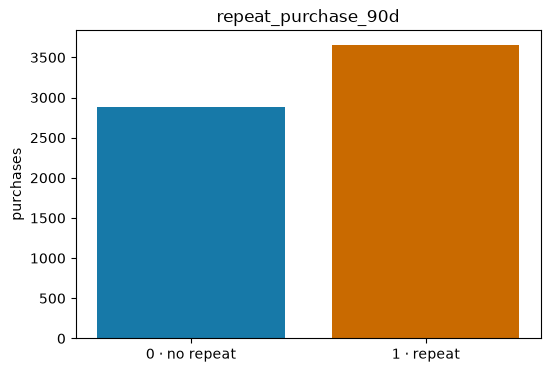

In [28]:
balance = train[target].value_counts().sort_index()
print(balance.to_frame("rows").assign(percentage=(100 * balance / len(train)).round(1)))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["0 · no repeat", "1 · repeat"], balance.values, color=[PLOT_BLUE, PLOT_ORANGE])
ax.set(ylabel="purchases", title="repeat_purchase_90d")
plt.show()

# Univariate Analysis

**This is the same as the train data but without the 65 missing rows and the impossible values**

In [29]:
candidate = train[~empty_rows].copy()
for column in ["prior_mean_purchase_value", "spend_365d", "days_since_previous_purchase", "prior_mean_gap_days"]:
    impossible = (candidate[column] < 0) | (candidate[column] >= 1e9)
    candidate.loc[impossible, column] = np.nan

## Numeric Variables

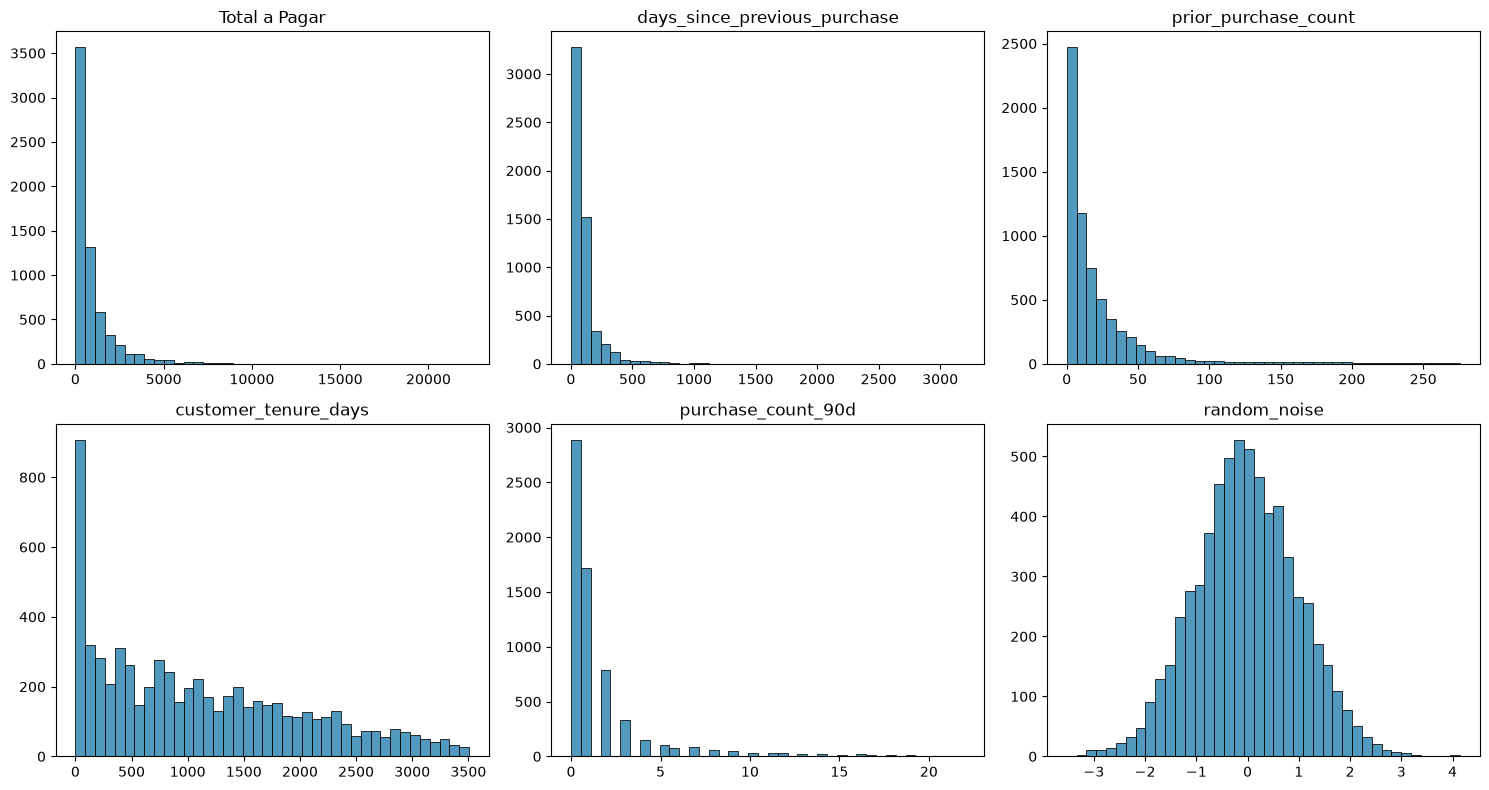

In [30]:
to_plot = ["Total a Pagar", "days_since_previous_purchase", "prior_purchase_count",
           "customer_tenure_days", "purchase_count_90d", "random_noise"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flatten(), to_plot):
    sns.histplot(candidate[column], bins=40, color=PLOT_BLUE, ax=ax)
    ax.set(title=column, xlabel="", ylabel="")
plt.tight_layout()
plt.show()

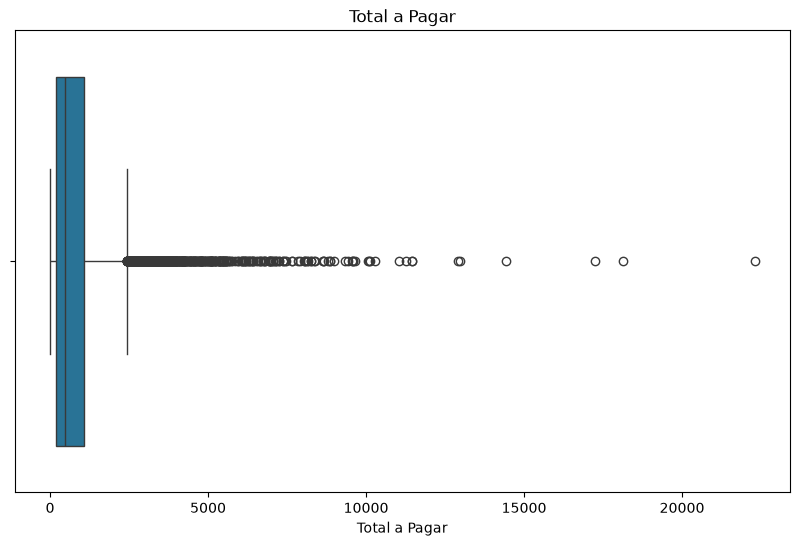

In [31]:
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.boxplot(x=candidate["Total a Pagar"], color=PLOT_BLUE, ax=ax)
ax.set(title="Total a Pagar")
plt.show()

## Categorical Variables

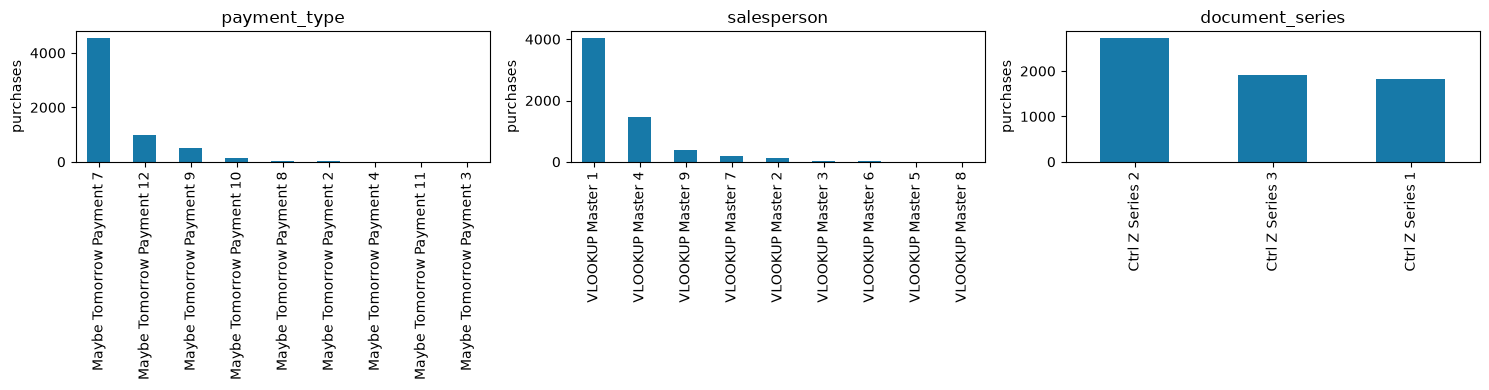

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["payment_type", "salesperson", "document_series"]):
    candidate[column].value_counts().plot(kind="bar", color=PLOT_BLUE, ax=ax)
    ax.set(title=column, xlabel="", ylabel="purchases")
plt.tight_layout()
plt.show()

# Multivariate Analysis

## Numeric Variables against the Target

In [33]:
compare = ["days_since_previous_purchase", "prior_mean_gap_days", "prior_purchase_count",
           "purchase_count_90d", "Total a Pagar", "random_noise"]
candidate.groupby(target)[compare].median().T.round(2)

repeat_purchase_90d,0,1
days_since_previous_purchase,105.00,37.00
prior_mean_gap_days,101.75,55.76
prior_purchase_count,6.00,17.00
purchase_count_90d,0.00,1.00
Total a Pagar,443.12,517.46
random_noise,-0.04,-0.05


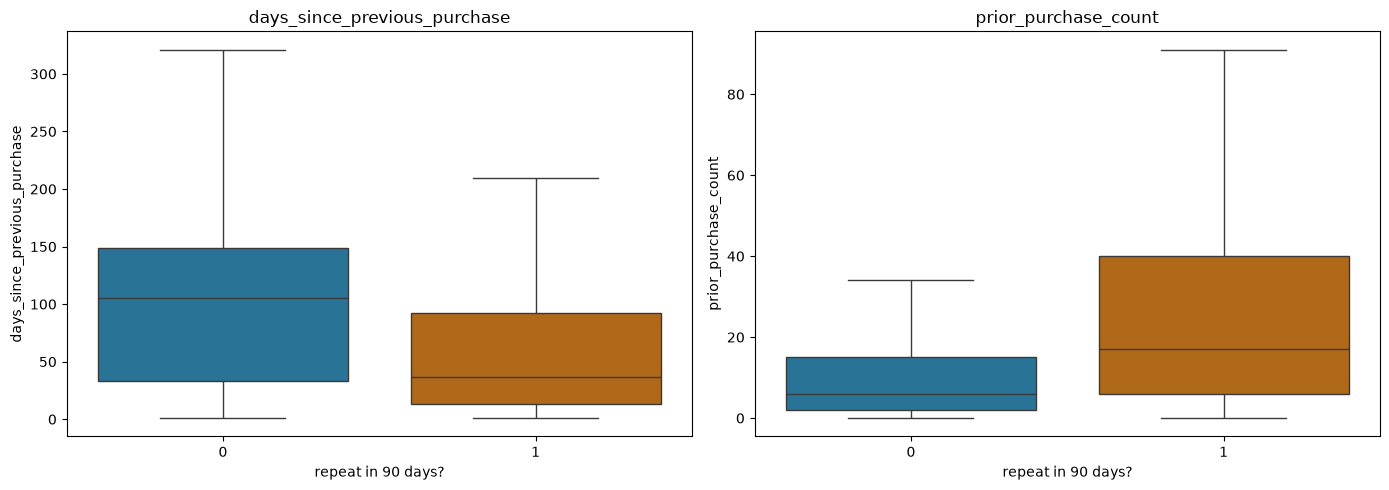

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column in zip(axes, ["days_since_previous_purchase", "prior_purchase_count"]):
    sns.boxplot(data=candidate, x=target, y=column, hue=target,
                palette=[PLOT_BLUE, PLOT_ORANGE], legend=False, showfliers=False, ax=ax)
    ax.set(title=column, xlabel="repeat in 90 days?")
plt.tight_layout()
plt.show()

## Correlation with the Target

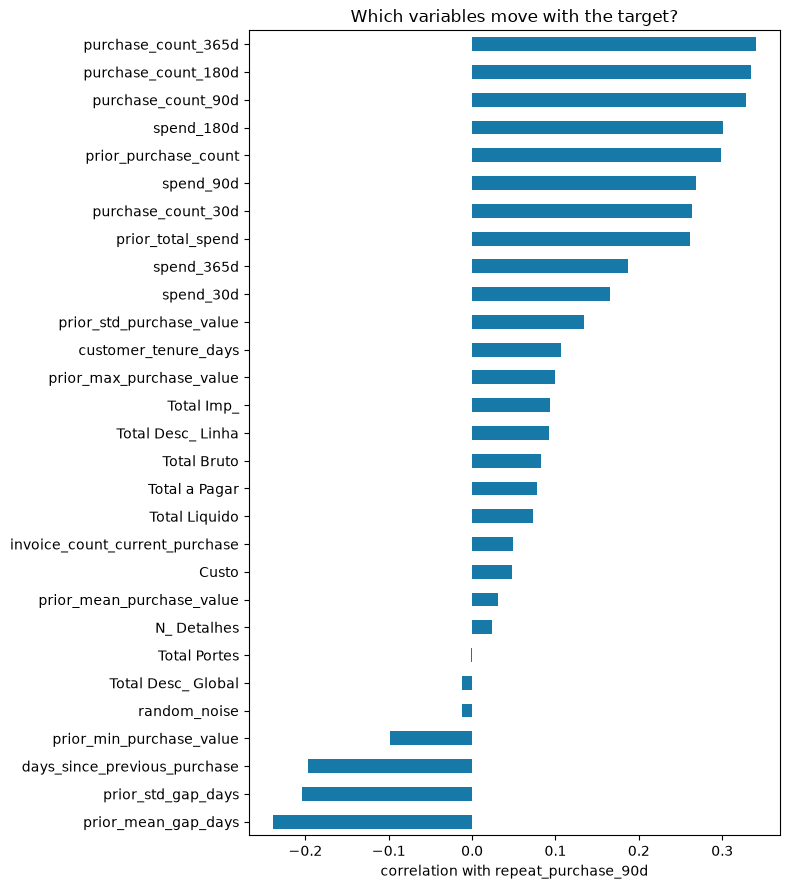

In [35]:
with_target = candidate[numeric + [target]].corr()[target].drop(target).sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
with_target.plot(kind="barh", color=PLOT_BLUE, ax=ax)
ax.set(xlabel="correlation with repeat_purchase_90d", title="Which variables move with the target?")
plt.tight_layout()
plt.show()

## Correlation between the Numeric Variables

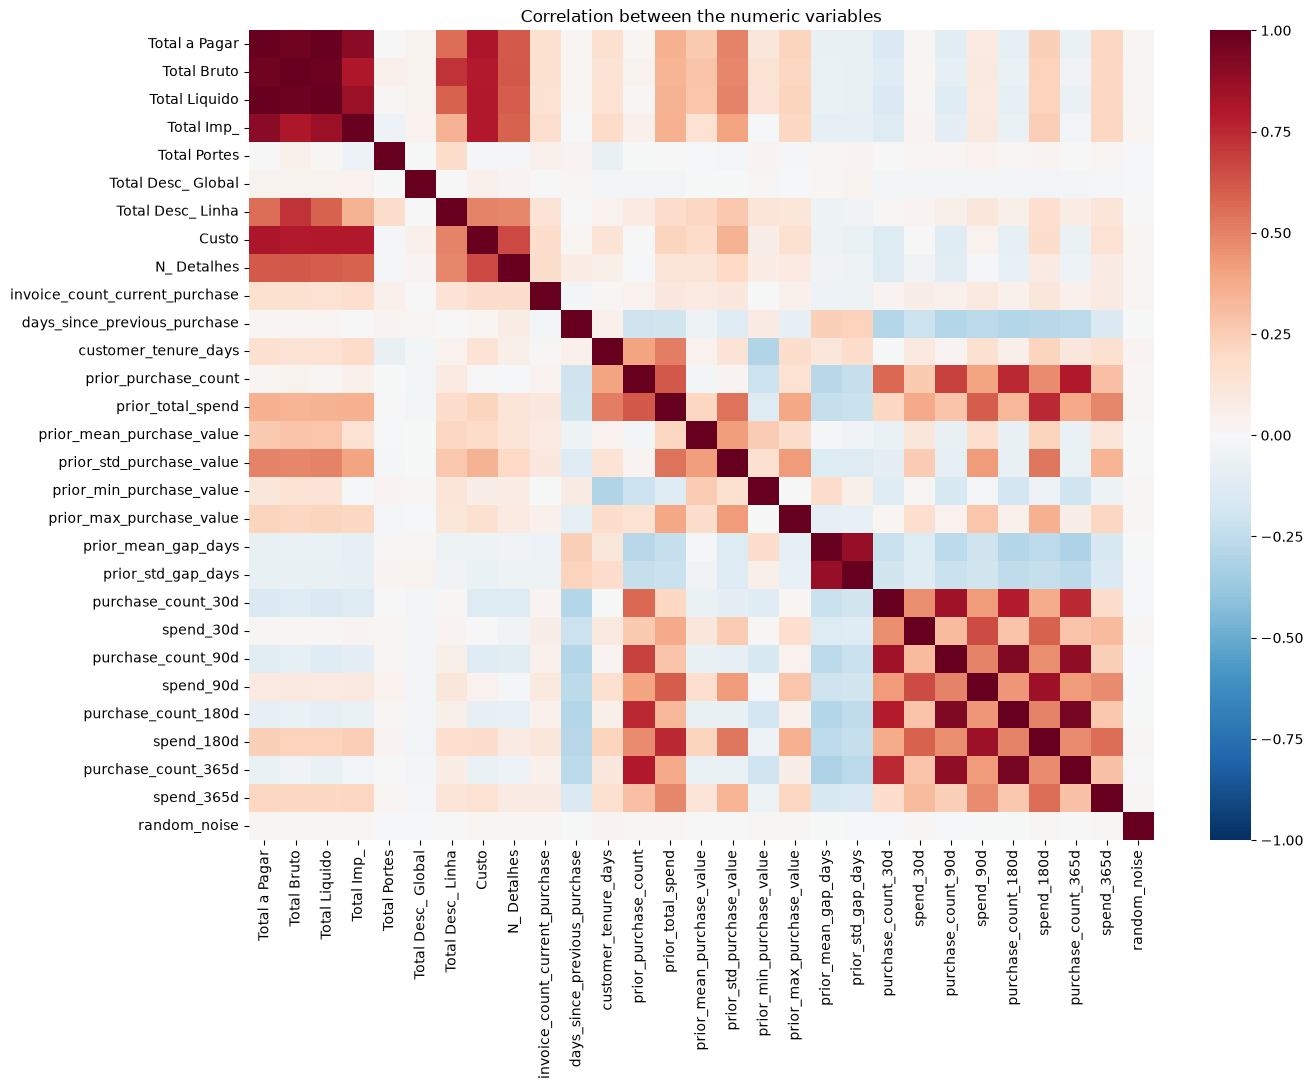

In [36]:
correlations = candidate[numeric].corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(correlations, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between the numeric variables")
plt.tight_layout()
plt.show()

In [37]:
pairs = correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.9].sort_values(ascending=False).round(2).to_frame("correlation")

,,correlation
Total a Pagar,Total Liquido,1.00
Total Bruto,Total Liquido,0.98
Total a Pagar,Total Bruto,0.97
purchase_count_180d,purchase_count_365d,0.95
purchase_count_90d,purchase_count_180d,0.94
Total a Pagar,Total Imp_,0.90


## Categorical Variables against the Target

In [38]:
for column in ["payment_type", "document_series"]:
    rates = candidate.groupby(column)[target].agg(["mean", "count"])
    rates.columns = ["repeat rate", "purchases"]
    display(rates.sort_values("purchases", ascending=False).round(2))

,repeat rate,purchases
payment_type,,
Maybe Tomorrow Payment 7,0.53,4565
Maybe Tomorrow Payment 12,0.54,991
Maybe Tomorrow Payment 9,0.95,502
Maybe Tomorrow Payment 10,0.40,134
Maybe Tomorrow Payment 8,0.32,40
Maybe Tomorrow Payment 2,0.52,21
Maybe Tomorrow Payment 4,0.44,9
Maybe Tomorrow Payment 11,0.62,8
Maybe Tomorrow Payment 3,0.50,4


,repeat rate,purchases
document_series,,
Ctrl Z Series 2,0.56,2738
Ctrl Z Series 3,0.56,1903
Ctrl Z Series 1,0.56,1828


## Train and Test over time

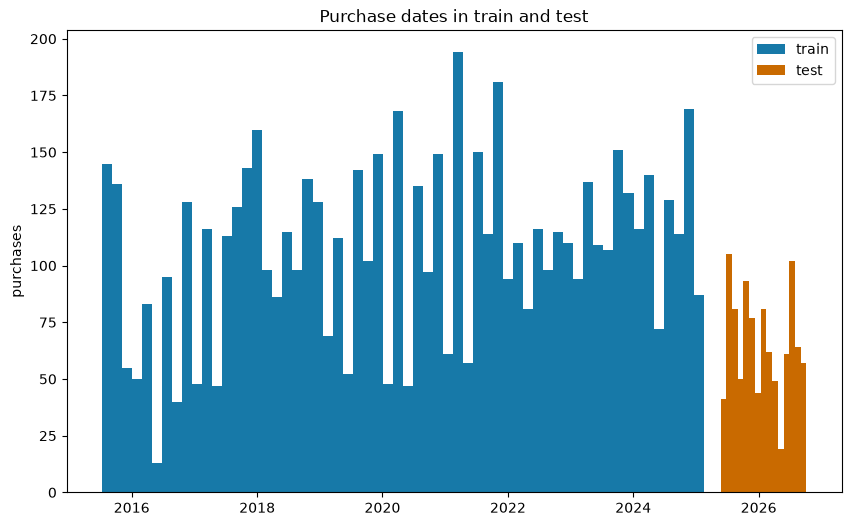

In [39]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.hist(train["purchase_date"].dropna(), bins=60, color=PLOT_BLUE, label="train")
ax.hist(test["purchase_date"], bins=15, color=PLOT_ORANGE, label="test")
ax.set(title="Purchase dates in train and test", ylabel="purchases")
ax.legend()
plt.show()

# The Clientes.csv Data

In [40]:
clientes.head()

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


In [41]:
print("one row per customer:", clientes["customer_id"].is_unique)
print("train customers found in clientes:", train["customer_id"].isin(clientes["customer_id"]).mean())
print("test customers found in clientes: ", test["customer_id"].isin(clientes["customer_id"]).mean())

pd.DataFrame({
    "% missing": (100 * clientes.isna().mean()).round(1),
    "different values": clientes.nunique(),
})

one row per customer: True
train customers found in clientes: 1.0
test customers found in clientes:  1.0


,% missing,different values
customer_id,0.0,1143
country_or_region,0.0,11
commercial_region,10.0,37
island,50.6,10
municipality,13.9,183
city,47.8,417
postal_area,6.2,271
postal_code,14.9,828
street,52.3,511
address,0.5,1120


# Summary of the Insights obtained